## JSD with Delta + Functional-Group grouping
**Version:** 1.0.0

**Release date:** 2026-11-01

**Changes in this version:** None

- **Pure CH ions** (no O / N / S / heteroatoms / isotopes) are grouped by their
  **delta value** (level of unsaturation), e.g. `CH Δ=-2`.
- **O-containing ions** are grouped by their **functional group**
  (`acid`, `ketone`, `alcohol`, `other`) using the DFG `np.select` rules.
- Hetero / isotope ions (N, S, Cl, j-isotopes, ...) → `other`.

Per-ion overrides from the DFG notebook (CHO→alcohol, C2H4O2→acid, etc.) are
applied. The aggregate signal-reapportionment corrections (C2H3O shift, the
delta=-8 alkyl→aromatic move, the levoglucosan f60 move) are **not** applied,
because a JSD partition needs every ion in exactly one fixed group and those
corrections move fractions of signal between groups.


In [14]:
# =============================================================================
# SECTION 0: Mount Google Drive
# -----------------------------------------------------------------------------
# Connects this Colab notebook to your Google Drive so the code can read the
# input CSV files and save output plots/tables. You will be prompted to
# authorize access the first time this runs in a session.
# =============================================================================
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
# =============================================================================
# SECTION 1: Imports and warning suppression
# -----------------------------------------------------------------------------
# Standard scientific-Python stack: numpy for math, pandas for tables,
# matplotlib for plotting, re for parsing chemical formulas with regular
# expressions. The warning filters just hide harmless pandas/matplotlib
# deprecation chatter so the output stays readable.
# =============================================================================
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)

In [16]:
# =============================================================================
# SECTION 2: User settings — input files, labels, and pre-processing options
# -----------------------------------------------------------------------------
# Import your data. CSV columns: mass, formula, frac_abundance
# (abundance need not be pre-normalized; it is renormalized below).
# Set up two spectra to compare, both CSVs in the same folder.
# =============================================================================
data_path   = '/content/drive/My Drive/Research/Testing_delta2/'   # folder with the CSVs
output_path = '/content/drive/My Drive/Research/Testing_delta2/'   # where plots/tables save

# The two spectra to compare. CSV columns: mass, formula, frac_abundance
csv_P = 'A-pin_highNOx.csv'    # spectrum A / P
csv_Q = 'IEPOX_SOA.csv'    # spectrum B / Q

# Figure / file labels. Leave as None to AUTO-name from the CSV filename
# (e.g. 'FP_14.csv' -> 'FP 14'). Or set a string to override, e.g. 'Milagro HOA'.
# These labels are spliced into every plot title and saved filename, so changing
# them here updates everything. (Resolved in Section 6.)
label_P = None
label_Q = None

# Fraction of lowest signals to remove before renormalization (e.g., 0.1 for 10%)
TRIM_FRACTION = 0 # @param {type:"number"}

# Toggle to remove +3 delta (noise) Only togggle this on for CH_only and mass_greater_than_48.
#Delta +3 for CH ions tends to be noise in the AMS
REMOVE_PLUS_3_DELTA = False # @param {type:"boolean"}

# Toggle for BBOA rule: C2H4O2 = alcohol if True, else C2H4O2 = acid
#set this to true if you know the sample is BBOA
BBOA_OPTION = False # @param {type:"boolean"}

In [17]:
# =============================================================================
# SECTION 3: Ion selection rules (carbon filter + mass filter)
# -----------------------------------------------------------------------------
# Loads the two raw CSVs and applies the ion selection rules chosen in the
# dropdowns below. This cell is mainly a quick look at the data: it reports
# the minimum fractional abundance surviving the filters for each spectrum.
# The SAME rules are re-applied inside prepare_spectrum() (Section 7) so that
# the full analysis pipeline uses identical selections.
# =============================================================================
a = pd.read_csv(data_path + csv_P)
b = pd.read_csv(data_path + csv_Q)

# Option to filter for 'CH_only' ions or 'all_carbon' containing ions.
# NOTE: for the combined Delta+FG grouping you want 'all_carbon' (so O-containing
# ions are present and get functional-group labels). 'CH_only' leaves only CH
# ions, in which case every group is a 'CH Δ=' delta group.
carbon_filter_option = 'all_carbon' # @param ['CH_only', 'all_carbon']

# Option to filter for mass >= 48 or all masses
mass_filter_option = 'all_masses' # @param ['mass_greater_than_48', 'all_masses']

if carbon_filter_option == 'CH_only':
    # Keep only C/CH ions, incl. carbon-only ions like C+ and digit-less CH+ (adjust this filter to match your formula style)
    a = a[a["formula"].str.match(r'^C\d*(H\d*)?\+?$', na=False)].copy()
    b = b[b["formula"].str.match(r'^C\d*(H\d*)?\+?$', na=False)].copy()
elif carbon_filter_option == 'all_carbon':
    # Keep all carbon-containing ions (formula starts with C followed by digits or just C)
    a = a[a["formula"].str.match(r'^C\d*.*$', na=False)].copy()
    b = b[b["formula"].str.match(r'^C\d*.*$', na=False)].copy()
else:
    print("Invalid carbon_filter_option. No filter applied.")

if mass_filter_option == 'mass_greater_than_48':
    a = a[a["mass"] >= 48].copy()
    b = b[b["mass"] >= 48].copy()

print(f"Minimum frac_abundance for 'a': {a['frac_abundance'].min():.2e}")
print(f"Minimum frac_abundance for 'b': {b['frac_abundance'].min():.2e}")

Minimum frac_abundance for 'a': 1.82e-07
Minimum frac_abundance for 'b': 4.64e-11


In [18]:
# =============================================================================
# SECTION 4: Analysis constants — element exclusions, delta lumping, plot detail
# -----------------------------------------------------------------------------
# ---- Filtering (applied identically to BOTH spectra so all numbers agree) ----
# The mass and carbon filters themselves are controlled by the @param dropdowns
# in Section 3 (`mass_filter_option` and `carbon_filter_option`).
# =============================================================================
EXCLUDE_ELEMENTS = ['S', 'Cl', 'Cu', 'N', 'P']   # drop ions containing any of these
                                                 # -> set to [] to keep everything (incl. N)
DELTA_LUMP_LOW, DELTA_LUMP_HIGH = -8, 7          # delta outside this range is lumped to edges

# Partition used for the decomposition.
#   ('group',)      -> combined Delta(CH) + functional-group(O-containing)  <-- THIS NOTEBOOK
#   ('O','delta')   -> finest original partition
#   ('delta',)      -> delta only (use this with carbon_filter_option='CH_only')
GROUP_COLS = ('group',)

# ---- Groups to hide from the FIGURES ----------------------------------------
# These ions stay in the analysis (total JSD and every reported number are
# unchanged); they simply get no bar / label / color of their own in the plots.
# Percentages shown in the plots are still fractions of the TRUE total JSD, so
# hidden groups just mean the visible bars no longer add to exactly 100%.
# Set HIDE_GROUPS = [] to show everything again.
HIDE_GROUPS = ['not carbon', 'unknown']

# Plot / table detail — how many rows/bars/groups to show in each output
TOP_N_TABLE       = 15   # rows in the printed within-group table
TOP_N_DECOMP_BARS = 12   # bars in the decomposition chart
TOP_N_CHAN_GROUPS = 8    # distinctly-colored groups in the channel plot
TOP_N_TWIN        = 12   # bars in the twin chart

In [19]:
# =============================================================================
# SECTION 5: Plot style — font family and font sizes (ONE PLACE to adjust)
# -----------------------------------------------------------------------------
# Change BASE_FONT_SIZE and every plot rescales at once. Each text element is
# defined as an offset from the base, so their relative sizes stay sensible;
# override any individual FS_* line if one element needs special treatment.
# =============================================================================
BASE_FONT_SIZE = 14 # @param {type:"number"}

FS_TITLE      = BASE_FONT_SIZE + 2   # plot titles / figure suptitles
FS_AXIS_LABEL = BASE_FONT_SIZE + 2   # x- and y-axis labels
FS_TICK       = BASE_FONT_SIZE       # tick labels (incl. bar-category labels)
FS_LEGEND     = BASE_FONT_SIZE - 2   # legend text
FS_BAR_LABEL  = BASE_FONT_SIZE - 2   # value/percent labels drawn next to bars
FS_ANNOTATION = BASE_FONT_SIZE - 6   # small formula annotations on channel plot

SHOW_YGRID = False # @param {type:"boolean"}   # horizontal grid on the fingerprint plot

# -----------------------------------------------------------------------------
# Font family: Arial.
# Colab machines don't ship Arial, so the block below installs Microsoft's core
# fonts (which include Arial) the first time it runs in a session. If the
# install ever fails, matplotlib falls back to 'Liberation Sans', a
# metrically-identical clone of Arial that IS pre-installed on Colab.
# -----------------------------------------------------------------------------
import matplotlib.font_manager as fm

def _arial_available():
    """True if any installed font is named Arial."""
    return any('arial' == f.name.lower() for f in fm.fontManager.ttflist)

if not _arial_available():
    # Pre-accept the Microsoft font EULA so the install runs without prompting.
    !echo ttf-mscorefonts-installer msttcorefonts/accepted-mscorefonts-eula select true | debconf-set-selections
    !apt-get -qq -y install ttf-mscorefonts-installer > /dev/null 2>&1
    !fc-cache -f > /dev/null 2>&1
    fm._load_fontmanager(try_read_cache=False)   # make matplotlib re-scan fonts

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans']

# Apply the sizes globally: every plot in this notebook inherits these, so the
# plotting functions below don't need (and don't use) hard-coded font sizes.
plt.rcParams.update({
    'font.size':        BASE_FONT_SIZE,
    'axes.titlesize':   FS_TITLE,
    'axes.labelsize':   FS_AXIS_LABEL,
    'xtick.labelsize':  FS_TICK,
    'ytick.labelsize':  FS_TICK,
    'legend.fontsize':  FS_LEGEND,
    'figure.titlesize': FS_TITLE,
})

print(f"Font set to: {plt.rcParams['font.sans-serif'][0] if _arial_available() else 'Liberation Sans (Arial clone)'}, "
      f"base size {BASE_FONT_SIZE}")

Font set to: Liberation Sans (Arial clone), base size 14


In [20]:
# =============================================================================
# SECTION 6: Resolve labels and units
# -----------------------------------------------------------------------------
# If label_P / label_Q were left as None in Section 2, build them from the CSV
# filenames (underscores become spaces). Also builds `tag`, the filename-safe
# label pair used when saving figures/tables, and sets the log base that
# defines the units for every divergence in the notebook.
# =============================================================================
if label_P is None:
    label_P = os.path.splitext(csv_P)[0].replace('_', ' ')
if label_Q is None:
    label_Q = os.path.splitext(csv_Q)[0].replace('_', ' ')

def _safe(s):
    """Make a label safe to use inside a filename."""
    return s.replace(' ', '_').replace('/', '-').replace('\\', '-')

tag = f'{_safe(label_P)}_vs_{_safe(label_Q)}'

# Units: log base 2 -> divergences are in BITS, bounded by 1.0;
# sqrt(JS divergence) is a metric also bounded by 1.0.
LOG = np.log2        # <-- the single switch that puts everything in bits
JSD_MAX = 1.0        # log2(2) = 1 bit

In [21]:
# =============================================================================
# SECTION 7: Formula parsing, COMBINED grouping, and spectrum preparation
# =============================================================================
def parse_formula(formula):
    """Extract C, H, O, N counts from a formula string."""
    counts = {'C': 0, 'H': 0, 'O': 0, 'N': 0}
    if not isinstance(formula, str):
        return counts
    for element, count in re.findall(r'([A-Z][a-z]*)(\d*)', formula):
        if element in counts:
            counts[element] += int(count) if count else 1
    return counts


# elements/markers that force an ion into 'other' (mirrors the DFG notebook:
# N, S, Cl, Cu, F, Br, I and the 'j' isotope flag are all 'other')
_HETERO_RE = re.compile(r'Cl|Cu|Br|Si|S|P|F|I')   # element symbols beyond C,H,O,N
_ISO_RE    = re.compile(r'j', re.IGNORECASE)        # isotope marker

def assign_group(df, bboa_option=False):
    """
    Return a single 'group' label per ion for the JSD partition.

    Rules (per-ion only):
      * pure CH ions (O==0, N==0, no heteroatoms, no isotope) -> 'CH Δ=<delta>'
      * O-containing ions -> functional group via the DFG np.select rules:
            O==1: delta<-2 'other'; -2..1 'acid'; ==2 'ketone'; >2 'alcohol'
            O==2: delta<3 'other'; 3 'acid'; 4 'acid'; >4 'alcohol'
            O>2 : 'other'
      * C==0 -> 'not carbon';  N/S/Cl/.../isotope -> 'other'
    Fixed per-ion overrides from the DFG notebook are applied last.
    Requires columns: formula, C, H, O, N, delta (delta already lumped).
    """
    d = df.copy()

    j_flag    = d['formula'].apply(lambda f: bool(_ISO_RE.search(f)) if isinstance(f, str) else False)
    het_flag  = d['formula'].apply(lambda f: bool(_HETERO_RE.search(f)) if isinstance(f, str) else False)
    # 'het_flag' may catch the N in formulas, but N is already handled via the column;
    # treat anything with N>0 OR a non-CHO element OR an isotope as 'other'.
    forces_other = (d['N'] > 0) | j_flag | het_flag
    is_ch = (d['O'] == 0) & (d['N'] == 0) & (d['C'] > 0) & (~forces_other)

    O = d['O']; delta = d['delta']
    conditions = [
        d['C'] == 0,                          # not carbon
        forces_other,                         # N / S / heteroatom / isotope
        (O == 1) & (delta < -2),              # other
        (O == 1) & (delta >= -2) & (delta <= 1),  # acid
        (O == 1) & (delta == 2),              # ketone
        (O == 1) & (delta > 2),               # alcohol
        (O == 2) & (delta < 3),               # other
        (O == 2) & (delta == 3),              # acid
        (O == 2) & (delta == 4),              # acid
        (O == 2) & (delta > 4),               # alcohol
        (O > 2),                              # other
    ]
    choices = ['not carbon', 'other', 'other', 'acid', 'ketone', 'alcohol',
               'other', 'acid', 'acid', 'alcohol', 'other']
    grp = pd.Series(np.select(conditions, choices, default='unknown'), index=d.index)

    # CH ions: overwrite with their delta-value label
    grp.loc[is_ch] = 'CH Δ=' + d.loc[is_ch, 'delta'].astype(int).astype(str)

    # fixed per-ion overrides (formula compared ignoring a trailing '+')
    base = d['formula'].astype(str).str.replace(r'\+$', '', regex=True)
    overrides = {'C5H6O': 'alcohol', 'CO': 'unknown', 'CHO': 'alcohol'}
    if bboa_option:
        overrides['C2H4O2'] = 'alcohol'
    else:
        overrides['C2H4O2'] = 'acid'

    for f, g in overrides.items():
        grp.loc[base == f] = g

    return grp


def prepare_spectrum(csv_full_path, mass_filter_option, carbon_filter_option,
                     trim_fraction=0.0, remove_plus_3_delta=False, bboa_option=False):
    """Load a spectrum CSV, parse formulas, compute delta, filter, group, renormalize."""
    df = pd.read_csv(csv_full_path)

    df['mass'] = pd.to_numeric(df['mass'], errors='coerce')
    df = df.dropna(subset=['mass']).reset_index(drop=True)

    counts = df['formula'].apply(parse_formula).apply(pd.Series)
    df = pd.concat([df, counts], axis=1)
    for col in ['C', 'H', 'O', 'N']:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)

    df['delta'] = df['mass'] - 14 * (df['C'] + df['O'] + df['N']) + 1
    df['delta'] = (df['delta'].replace([np.inf, -np.inf], np.nan)
                              .round().fillna(0).astype(int))

    if mass_filter_option == 'mass_greater_than_48':
        df = df[df["mass"] >= 48].copy()

    # Apply carbon filter based on option (same rules as Section 3)
    if carbon_filter_option == 'CH_only':
        df = df[df["formula"].str.match(r'^C\d*(H\d*)?\+?$', na=False)].copy()
    elif carbon_filter_option == 'all_carbon':
        df = df[df["formula"].str.match(r'^C\d*.*$', na=False)].copy()

    for el in EXCLUDE_ELEMENTS:
        df = df[~df['formula'].str.contains(el, case=True, na=False)]

    df.loc[df['delta'] < DELTA_LUMP_LOW,  'delta'] = DELTA_LUMP_LOW
    df.loc[df['delta'] > DELTA_LUMP_HIGH, 'delta'] = DELTA_LUMP_HIGH

    if remove_plus_3_delta:
        df = df[df['delta'] != 3].copy()

    df['frac_abundance'] = df['frac_abundance'].apply(lambda x: max(0, x))

    if trim_fraction > 0:
        df = df.sort_values(by='frac_abundance', ascending=True).reset_index(drop=True)
        num_to_trim = int(len(df) * trim_fraction)
        df = df.iloc[num_to_trim:].copy()

    # ---- COMBINED grouping (delta for CH, functional group for O-containing) ----
    df = df.reset_index(drop=True)
    df['group'] = assign_group(df, bboa_option=bboa_option)

    total = df['frac_abundance'].sum()
    if total <= 0:
        raise ValueError(f"No mass remaining after filtering in {csv_full_path}")
    df['frac_abundance'] = df['frac_abundance'] / total
    return df.reset_index(drop=True)

In [22]:
# =============================================================================
# SECTION 8: Information-theoretic helpers (all in bits because LOG = np.log2)
# =============================================================================
def _kl(p, q, eps=1e-15):
    p = np.asarray(p, float); q = np.asarray(q, float)
    mask = p > 0
    return float(np.sum(p[mask] * LOG(p[mask] / np.maximum(q[mask], eps))))

def jsd(p, q):
    p = np.asarray(p, float); q = np.asarray(q, float)
    m = 0.5 * (p + q)
    return 0.5 * _kl(p, m) + 0.5 * _kl(q, m)

def cosine_similarity(df_P, df_Q):
    P = df_P[['formula', 'frac_abundance']].rename(columns={'frac_abundance': 'p'})
    Q = df_Q[['formula', 'frac_abundance']].rename(columns={'frac_abundance': 'q'})
    merged = pd.merge(P, Q, on='formula', how='outer').fillna(0.0)
    p, q = merged['p'].values, merged['q'].values
    return float(np.dot(p, q) / (np.linalg.norm(p) * np.linalg.norm(q)))

In [23]:
# =============================================================================
# SECTION 9: Per-channel table (shared by every plot and by the decomposition)
# =============================================================================
def per_channel_table(df_P, df_Q):
    P = df_P.rename(columns={'frac_abundance': 'p'})
    Q = df_Q.rename(columns={'frac_abundance': 'q'})
    merged = pd.merge(P, Q, on='formula', how='outer', suffixes=('_P', '_Q'))

    # Coalesce descriptor columns (same formula -> same descriptors in both files).
    # 'group' is carried through here so GROUP_COLS=('group',) works.
    desc_cols = ['mass', 'C', 'H', 'O', 'N', 'delta', 'group']
    for col in desc_cols:
        merged[col] = merged[f'{col}_P'].fillna(merged[f'{col}_Q'])
    merged = merged.drop(columns=[f'{c}_P' for c in desc_cols]
                                + [f'{c}_Q' for c in desc_cols])
    for col in ['C', 'H', 'O', 'N', 'delta']:
        merged[col] = merged[col].astype(int)
    merged['group'] = merged['group'].astype(str)

    merged['p'] = merged['p'].fillna(0.0)
    merged['q'] = merged['q'].fillna(0.0)

    p = merged['p'].values; q = merged['q'].values
    m = 0.5 * (p + q)
    eps = 1e-15
    with np.errstate(divide='ignore', invalid='ignore'):
        term_p = np.where(p > 0, p * LOG(p / np.maximum(m, eps)), 0.0)
        term_q = np.where(q > 0, q * LOG(q / np.maximum(m, eps)), 0.0)
    merged['contribution'] = 0.5 * (term_p + term_q)   # per-channel JSD, bits
    merged['residual'] = p - q                          # + => P-heavy, - => Q-heavy
    merged['enriched_in'] = np.where(p > q, 'A', np.where(q > p, 'B', 'equal'))
    return merged.sort_values('mass').reset_index(drop=True)

In [24]:
# =============================================================================
# SECTION 10: Decomposition — total = between-group + sum(within-group)
# =============================================================================
def jsd_decomposition(merged, group_cols=('group',)):
    total = jsd(merged['p'].values, merged['q'].values)

    marg = (merged.groupby(list(group_cols))[['p', 'q']].sum()
                  .reset_index().rename(columns={'p': 'P_G', 'q': 'Q_G'}))
    between = jsd(marg['P_G'].values, marg['Q_G'].values)

    rows = []
    for _, gm in marg.iterrows():
        key = tuple(gm[c] for c in group_cols)
        P_G, Q_G = float(gm['P_G']), float(gm['Q_G'])
        s_g = P_G + Q_G
        if s_g <= 0:
            continue
        mask = np.all([merged[c].values == k for c, k in zip(group_cols, key)], axis=0)
        p_chan = merged.loc[mask, 'p'].values
        q_chan = merged.loc[mask, 'q'].values
        if P_G == 0 or Q_G == 0:
            contribution = 0.0; jsd_pi = 0.0
        else:
            P_g = p_chan / P_G; Q_g = q_chan / Q_G
            pi_P = P_G / s_g;   pi_Q = Q_G / s_g
            M_g = pi_P * P_g + pi_Q * Q_g
            jsd_pi = pi_P * _kl(P_g, M_g) + pi_Q * _kl(Q_g, M_g)
            contribution = 0.5 * s_g * jsd_pi
        row = {c: k for c, k in zip(group_cols, key)}
        row.update({'P_G': P_G, 'Q_G': Q_G, 's_g': s_g,
                    'jsd_pi': jsd_pi, 'contribution': contribution})
        rows.append(row)

    wt = (pd.DataFrame(rows).sort_values('contribution', ascending=False)
                            .reset_index(drop=True))
    wt['pct_of_total'] = 100.0 * wt['contribution'] / total
    wt['m_delta'] = 0.5 * wt['s_g']        # prevalence weight (mixture mass share)
    wt['jsd_w']   = wt['jsd_pi']           # within-group divergence, UNWEIGHTED (bits)
    reconstructed = between + wt['contribution'].sum()
    return {'total_jsd': total, 'between_jsd': between,
            'between_pct_of_total': 100.0 * between / total,
            'within_table': wt, 'reconstructed_total': reconstructed,
            'reconstruction_error': abs(reconstructed - total)}

In [25]:
import matplotlib.pyplot as plt

# =============================================================================
# SECTION 11: Reporting + plotting helpers
# -----------------------------------------------------------------------------
# FONT SIZES: all font family/size choices live in SECTION 5 (plot style).
# Titles, axis labels, tick labels, and legends inherit the rcParams set
# there; text drawn manually (bar labels, formula annotations) uses the FS_*
# variables. Nothing in this cell hard-codes a font size.
#
# HIDDEN GROUPS: groups listed in HIDE_GROUPS (Section 4) are dropped from the
# figures only. They remain in the analysis, so total JSD and the printed
# numbers are unaffected; the visible bars simply no longer sum to 100%.
#
# Functions:
#   print_report()          : text summary of the JSD numbers
#   plot_per_group_signed() : diverging bars — per-group JSD split by which
#                             spectrum is enriched (CH ions by delta, then
#                             the functional-group slots)
#   plot_decomposition()    : horizontal bars — between-group vs each
#                             within-group contribution to the total JSD
#   plot_twin_within_group(): contribution (m x JSD_w) vs within-group JSD_w
#   plot_channel_residuals(): per-ion residual and contribution vs m/z
# =============================================================================
_GCOL_CANDIDATES = ('O', 'delta', 'group')

def _gcols(df):
    return [c for c in _GCOL_CANDIDATES if c in df.columns]

def _row_label(r, gcols, with_m=False):
    """Build a readable label for a within-group row from whatever gcols exist."""
    if 'group' in gcols:
        s = str(r['group'])
    elif 'O' in gcols and 'delta' in gcols:
        s = f"O={int(r['O'])}, Δ={int(r['delta'])}"
    elif 'delta' in gcols:
        s = f"Δ={int(r['delta'])}"
    elif 'O' in gcols:
        s = f"O={int(r['O'])}"
    else:
        s = str(tuple(r[c] for c in gcols))
    if with_m and 'm_delta' in r:
        s += f" (m={r['m_delta']:.3f})"
    return s

def _row_height(base=0.35):
    """Bar-row height in inches, scaled with BASE_FONT_SIZE.

    At BASE_FONT_SIZE = 14 this reproduces the spacing used in
    JSD_combined_version5; raising the font size opens the rows up so the
    category labels never overlap.
    """
    return base * max(1.0, BASE_FONT_SIZE / 14.0)

def _visible(df, hide=None):
    """Drop the groups listed in HIDE_GROUPS from a table headed for a figure.

    Display-only: the analysis tables themselves are never modified.
    """
    hide = HIDE_GROUPS if hide == None else hide
    if not hide or 'group' not in df.columns:
        return df
    return df[~df['group'].astype(str).isin(hide)].copy()

def print_report(result, p_label, q_label, cos_sim, top_n=15, show_table=True):
    """Print the headline JSD numbers and the between/within split."""
    print('=' * 64)
    print(f"JSD Decomposition (bits):  {p_label} (A)  vs  {q_label} (B)")
    print('=' * 64)
    js_dist = np.sqrt(result['total_jsd'])
    print(f"Total JS divergence    : {result['total_jsd']:.6f} bits   (max {JSD_MAX:.3f})")
    print(f"JS distance  sqrt(div) : {js_dist:.6f}        (a metric, max 1)")
    print(f"JS similarity  1-dist  : {1 - js_dist:.6f}")
    print(f"Cosine similarity      : {cos_sim:.6f}")
    print()
    print(f"Between-group JSD      : {result['between_jsd']:.6f} bits "
          f"({result['between_pct_of_total']:.1f}% of total)")
    within_sum = result['within_table']['contribution'].sum()
    print(f"Within-group total     : {within_sum:.6f} bits "
          f"({100 - result['between_pct_of_total']:.1f}% of total)")
    print(f"Reconstruction check   : between + within = "
          f"{result['reconstructed_total']:.6f}  (error {result['reconstruction_error']:.2e})")
    if show_table:
        print(f"\nTop {top_n} within-group contributors:")
        gcols = _gcols(result['within_table'])
        cols = gcols + ['P_G','Q_G','m_delta','jsd_w','contribution','pct_of_total']
        with pd.option_context('display.float_format', '{:.6f}'.format):
            print(result['within_table'][cols].head(top_n).to_string(index=False))

# order in which functional-group slots appear AFTER the CH delta bars
FG_SLOT_ORDER = ['acid', 'ketone', 'alcohol', 'other', 'unknown', 'not carbon']

def _group_sort_key(name):
    """CH delta groups first (ordered by numeric delta), then functional-group slots."""
    if isinstance(name, str) and name.startswith('CH Δ='):
        try:
            return (0, int(name.split('=', 1)[1]))
        except ValueError:
            return (0, 0)
    return (1, FG_SLOT_ORDER.index(name) if name in FG_SLOT_ORDER else 99)

def plot_per_group_signed(merged, p_label, q_label, save_path=None, hide=None):
    """
    Diverging signed JSD fingerprint by the COMBINED group:
      CH ions -> one bar per delta value, then separate slots for the
      functional groups (acid, ketone, alcohol, other, ...).
    Positive bars = enriched in A (P); negative = enriched in B (Q).
    Percentages are of the TRUE total JSD, including any hidden groups.
    """
    grp = merged.groupby('group')
    dd = pd.DataFrame({
        'group': list(grp.groups.keys()),
        'total': grp['contribution'].sum().values,
        'A': grp.apply(lambda g: g.loc[g['enriched_in'] == 'A', 'contribution'].sum()).values,
        'B': grp.apply(lambda g: g.loc[g['enriched_in'] == 'B', 'contribution'].sum()).values,
    })

    # Total is taken BEFORE hiding, so percentages stay true to the real total JSD
    total_jsd = dd['total'].sum()

    dd = _visible(dd, hide)

    dd['_o0'] = dd['group'].map(lambda n: _group_sort_key(n)[0])
    dd['_o1'] = dd['group'].map(lambda n: _group_sort_key(n)[1])
    dd = dd.sort_values(['_o0', '_o1']).drop(columns=['_o0', '_o1']).reset_index(drop=True)

    dd['pct']   = 100.0 * dd['total'] / total_jsd
    dd['pct_A'] =  100.0 * dd['A'] / total_jsd   # plotted positive
    dd['pct_B'] = -100.0 * dd['B'] / total_jsd   # plotted negative

    is_ch  = dd['group'].str.startswith('CH Δ=')
    labels = [g.replace('CH Δ=', '') if c else g for g, c in zip(dd['group'], is_ch)]
    n_ch   = int(is_ch.sum())

    # Widen the figure when there are many groups so the larger tick labels fit
    x = np.arange(len(dd))
    fig, ax = plt.subplots(figsize=(max(7, 0.02 * len(dd) * max(1.0, BASE_FONT_SIZE / 14.0)), 5.5))
    ax.bar(x, dd['pct_A'], width=0.75, color='#000080', alpha=0.85,
           label=f'enriched in {p_label} (A)')
    ax.bar(x, dd['pct_B'], width=0.75, color='teal', alpha=0.85,
           label=f'enriched in {q_label} (B)')
    ax.axhline(0, color='black', linewidth=0.8)

    # Divider + section headers between the CH delta bars and the FG slots.
    # Headroom is added first so the headers sit inside the axes and never
    # collide with the title (they used to overlap it at larger font sizes).
    if 0 < n_ch < len(dd):
        y0, y1 = ax.get_ylim()
        ax.set_ylim(y0, y1 * 1.20)
        ytxt = ax.get_ylim()[1] * 0.98
        ax.axvline(n_ch - 0.5, color='gray', linestyle='--', linewidth=1)
        ax.text((n_ch - 1) / 2.0, ytxt, 'CH ions (Δ)', ha='center', va='top',
                fontsize=FS_LEGEND, color='gray')
        ax.text((n_ch + len(dd) - 1) / 2.0, ytxt, 'functional groups', ha='center',
                va='top', fontsize=FS_LEGEND, color='gray')

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_xlabel('CH ions by delta value   |   functional groups')
    ax.set_ylabel('% of total JSD\n(+ enriched in A, − enriched in B)')
    ax.set_title(f'Per-group JSD fingerprint (bits)  |  total JSD = {total_jsd:.4f}\n'
                 f'A = {p_label}   B = {q_label}')
    ax.legend(loc='best')
    if SHOW_YGRID:
        ax.grid(True, axis='y', alpha=0.3)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Plot saved to: {save_path}")
    plt.show()
    return dd

def plot_decomposition(result, p_label, q_label, top_n=12, save_path=None, hide=None):
    """Horizontal bar chart: between-group bar + top within-group contributors.

    Bars are shaded by m_delta (prevalence): darker blue = the family carries
    more of the total mixture mass.
    """
    wt = _visible(result['within_table'].copy(), hide).reset_index(drop=True)
    top = wt.head(top_n).copy()
    other = wt.iloc[top_n:]['contribution'].sum() if len(wt) > top_n else 0.0
    gcols = _gcols(wt)

    # The between-group bar is drawn first, in dark grey with white hatching
    labels = ['between-group']; values = [result['between_jsd']]
    colors = ['#444444']; hatches = ['///']

    # Shade the within-group bars by m_delta (normalized to 0-1 for the colormap)
    if not top.empty:
        min_m, max_m = top['m_delta'].min(), top['m_delta'].max()
        if max_m == min_m:          # avoid divide-by-zero if all values are equal
            norm = np.zeros(len(top))
        else:
            norm = (top['m_delta'] - min_m) / (max_m - min_m)
        cmap = plt.cm.Blues          # can be changed to 'viridis', 'plasma', etc.
        within_colors = [cmap(v) for v in norm]
    else:
        within_colors = []

    for j, (_, r) in enumerate(top.iterrows()):
        labels.append(_row_label(r, gcols))
        values.append(r['contribution']); colors.append(within_colors[j]); hatches.append(None)

    # Collapse everything past top_n into a single grey "other" bar
    if other > 0:
        labels.append(f'other within-group ({len(wt) - top_n} groups)')
        values.append(other); colors.append('#aaaaaa'); hatches.append(None)

    fig, ax = plt.subplots(figsize=(8, max(3, _row_height(0.35) * len(labels))))
    bars = ax.barh(labels, values, color=colors, hatch=hatches)
    # Set edgecolor to white for the first bar to make the hatches white
    if len(bars) > 0 and hatches[0] is not None:
        bars[0].set_edgecolor('white')
    ax.invert_yaxis()
    ax.set_xlabel('Contribution to JSD (bits)')
    ax.set_title(f'JSD decomposition (bits): {p_label} vs {q_label}\n'
                 f'Total JSD = {result["total_jsd"]:.4f} bits')
    # Percent-of-total label at the end of each bar
    # (swap in the commented line to show the value in bits as well)
    for i, v in enumerate(values):
        ax.text(v, i, f'  {100 * v / result["total_jsd"]:.1f}%',
                va='center', fontsize=FS_BAR_LABEL)
        # ax.text(v, i, f'  {v:.4f} ({100 * v / result["total_jsd"]:.1f}%)',
        #         va='center', fontsize=FS_BAR_LABEL)
    ax.set_xlim(0, max(values) * 1.35)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Plot saved to: {save_path}")
    plt.show()

def plot_twin_within_group(result, p_label, q_label, top_n=12, save_path=None, hide=None):
    """Twin horizontal bar chart (groups in contribution order):
      Panel A: contribution to the total JSD (= m_delta x JSD_w)
      Panel B: the within-group divergence JSD_w on its own (mass-blind shape)
    Both panels are colored by m_delta (prevalence): darker = more prevalent.
    Families flagged in orange rank far higher by raw JSD_w than by contribution
    (a big shape difference in a family that carries little mass).
    """
    wt = _visible(result['within_table'], hide).head(top_n).copy().reset_index(drop=True)
    gcols = _gcols(wt)

    # rank-flip flag: ranks much higher by raw JSD_w than by contribution
    full = result['within_table']
    rc = full['contribution'].rank(ascending=False, method='min')
    rw = full['jsd_w'].rank(ascending=False, method='min')
    flip = []
    for i in range(len(wt)):
        mask = np.all([full[c].values == wt.loc[i, c] for c in gcols], axis=0)
        flip.append((float(rc[mask].iloc[0]) - float(rw[mask].iloc[0])) >= 10)

    y = np.arange(len(wt))
    fig, (axA, axB) = plt.subplots(1, 2, figsize=(14, max(4, _row_height(0.6) * len(wt))), sharey=True)

    if not wt.empty:
        min_m, max_m = wt['m_delta'].min(), wt['m_delta'].max()
        norm = np.zeros(len(wt)) if max_m == min_m else (wt['m_delta'] - min_m) / (max_m - min_m)
        colorsA = [plt.cm.Blues(v) for v in norm]
        colorsB = [plt.cm.RdPu(v) for v in norm]
    else:
        colorsA = colorsB = []

    barsA = axA.barh(y, wt['contribution'], color=colorsA)
    barsB = axB.barh(y, wt['jsd_w'],        color=colorsB)

    axA.set_yticks(y)
    axA.set_yticklabels([_row_label(wt.loc[i], gcols, with_m=True) for i in range(len(wt))])
    axA.invert_yaxis()
    axA.set_title('A. Contribution to total JSD')
    axA.set_xlabel('Contribution to JSD (bits)\n= m · JSD_w')
    axB.set_title('B. Within-group divergence only')
    axB.set_xlabel('Within-group JSD_w (bits)\n= contribution ÷ m')

    # Value label at the end of each bar; fade bars for near-zero-mass families
    for i in y:
        barsB[i].set_alpha(0.3 if wt['m_delta'][i] < 0.009 else 1.0)
        axA.text(wt['contribution'][i], i, f"  {wt['contribution'][i]:.4f}",
                 va='center', fontsize=FS_BAR_LABEL, color='black')
        axB.text(wt['jsd_w'][i], i, f"  {wt['jsd_w'][i]:.4f}",
                 va='center', fontsize=FS_BAR_LABEL, color='black')
        if flip[i]:
            axA.get_yticklabels()[i].set_color('#a04020')
            axA.get_yticklabels()[i].set_fontweight('bold')
            barsB[i].set_edgecolor('#a04020'); barsB[i].set_linewidth(1.5)

    axA.set_xlim(0, max(wt['contribution'].max(), 1e-12) * 1.30)
    axB.set_xlim(0, max(wt['jsd_w'].max(),        1e-12) * 1.30)
    fig.suptitle(f'Decomposing contribution vs. shape-only divergence: {p_label} vs {q_label}')
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Twin plot saved to: {save_path}")
    plt.show()

def plot_channel_residuals(merged, result, p_label, q_label,
                           group_cols=('group',), top_n_groups=8, save_path=None, hide=None):
    """Two stacked panels vs m/z: per-ion residual (p - q) on top and per-ion
    JSD contribution below. Ions in the top_n_groups families get distinct
    colors; everything else (including hidden groups) is grey. The 5 most
    extreme ions in each panel are annotated with their formulas.
    """
    chan = merged.sort_values('mass').reset_index(drop=True)
    wt = _visible(result['within_table'], hide)
    top_keys = [tuple(r[c] for c in group_cols) for _, r in wt.head(top_n_groups).iterrows()]
    cmap = plt.get_cmap('tab10')
    color_lookup = {k: cmap(i % 10) for i, k in enumerate(top_keys)}
    other_color = '#cccccc'

    def _key(row): return tuple(row[c] for c in group_cols)
    def _label(k):
        if group_cols == ('group',):     return str(k[0])
        if group_cols == ('O', 'delta'): return f"O={int(k[0])}, Δ={int(k[1])}"
        if group_cols == ('delta',):     return f"Δ={int(k[0])}"
        if group_cols == ('O',):         return f"O={int(k[0])}"
        return str(k)

    colors = [color_lookup.get(_key(r), other_color) for _, r in chan.iterrows()]
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

    # ---- Top panel: signed residual (which spectrum is heavier at each ion) ----
    ax1.bar(chan['mass'], chan['residual'], color=colors, width=0.8)
    ax1.axhline(0, color='black', linewidth=0.5)
    # (label wrapped onto two lines so it doesn't run into the lower panel's
    #  y-label at larger font sizes)
    ax1.set_ylabel(f'p − q\n(positive → {p_label}-heavy)')
    ax1.set_title(f'Channel-level comparison (bits): {p_label} vs {q_label}\n'
                  f'Total JSD = {result["total_jsd"]:.4f} bits, '
                  f'cosine = {cosine_similarity(df_P, df_Q):.4f}')
    # Annotate the 5 largest |residual| ions with their formulas
    for _, r in chan.reindex(chan['residual'].abs().sort_values(ascending=False).index).head(5).iterrows():
        ax1.annotate(r['formula'], xy=(r['mass'], r['residual']),
                     xytext=(0, 5 if r['residual'] > 0 else -10),
                     textcoords='offset points', ha='center', fontsize=FS_ANNOTATION)

    # ---- Bottom panel: each ion's contribution to the total JSD ----
    ax2.bar(chan['mass'], chan['contribution'], color=colors, width=0.8)
    ax2.set_ylabel('Contribution to JSD (bits)')
    ax2.set_xlabel('m/z')
    # Annotate the 5 largest contributors
    for _, r in chan.sort_values('contribution', ascending=False).head(5).iterrows():
        ax2.annotate(r['formula'], xy=(r['mass'], r['contribution']),
                     xytext=(0, 4), textcoords='offset points', ha='center', fontsize=FS_ANNOTATION)

    # Legend: one swatch per colored family, plus grey 'other groups' if needed
    handles = [plt.Rectangle((0, 0), 1, 1, color=color_lookup[k]) for k in top_keys]
    leg = [_label(k) for k in top_keys]
    if any(_key(r) not in color_lookup for _, r in chan.iterrows()):
        handles.append(plt.Rectangle((0, 0), 1, 1, color=other_color)); leg.append('other groups')
    ax1.legend(handles, leg, loc='upper right', bbox_to_anchor=(1.18, 1.0), frameon=False)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Channel plot saved to: {save_path}")
    plt.show()
    return chan

Loaded A-pin highNOx (A): 223 channels  (sum = 1.000000)
Loaded IEPOX SOA (B): 251 channels  (sum = 1.000000)
JSD Decomposition (bits):  A-pin highNOx (A)  vs  IEPOX SOA (B)
Total JS divergence    : 0.090081 bits   (max 1.000)
JS distance  sqrt(div) : 0.300135        (a metric, max 1)
JS similarity  1-dist  : 0.699865
Cosine similarity      : 0.891944

Between-group JSD      : 0.022755 bits (25.3% of total)
Within-group total     : 0.067326 bits (74.7% of total)
Reconstruction check   : between + within = 0.090081  (error 1.39e-17)

Top 15 within-group contributors:
  group      P_G      Q_G  m_delta    jsd_w  contribution  pct_of_total
alcohol 0.113125 0.181157 0.147141 0.081162      0.011942     13.257206
 CH Δ=1 0.042808 0.012500 0.027654 0.427222      0.011814     13.115364
   acid 0.171961 0.182397 0.177179 0.065799      0.011658     12.941877
  other 0.042045 0.023080 0.032562 0.216993      0.007066      7.843865
CH Δ=-1 0.044896 0.046542 0.045719 0.128615      0.005880      6.52

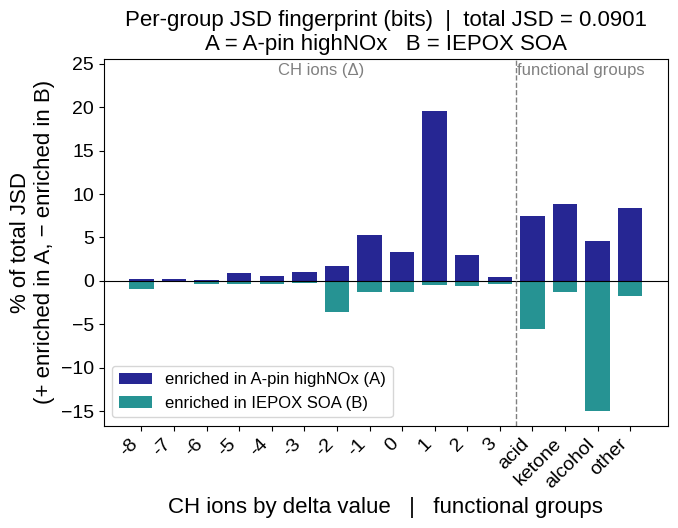

Plot saved to: /content/drive/My Drive/Research/Testing_delta2/jsd_decomposition_A-pin_highNOx_vs_IEPOX_SOA.png


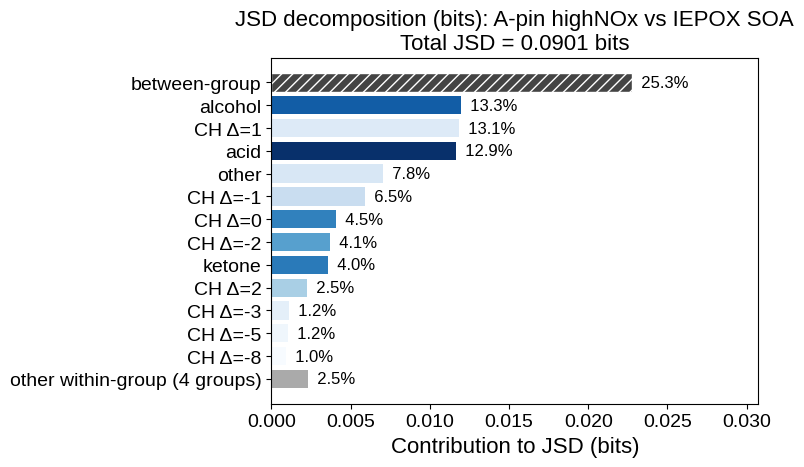

In [26]:
# =============================================================================
# SECTION 12: Run the analysis
# -----------------------------------------------------------------------------
# 1. Prepare both spectra with identical selection rules (Sections 3-4, 7)
# 2. Build the per-channel table and the between/within decomposition
# 3. Print the report, then draw whichever plots are toggled on below
# =============================================================================
df_P = prepare_spectrum(data_path + csv_P, mass_filter_option, carbon_filter_option,
                        trim_fraction=TRIM_FRACTION, remove_plus_3_delta=REMOVE_PLUS_3_DELTA,
                        bboa_option=BBOA_OPTION)
df_Q = prepare_spectrum(data_path + csv_Q, mass_filter_option, carbon_filter_option,
                        trim_fraction=TRIM_FRACTION, remove_plus_3_delta=REMOVE_PLUS_3_DELTA,
                        bboa_option=BBOA_OPTION)
print(f"Loaded {label_P} (A): {len(df_P)} channels  (sum = {df_P['frac_abundance'].sum():.6f})")
print(f"Loaded {label_Q} (B): {len(df_Q)} channels  (sum = {df_Q['frac_abundance'].sum():.6f})")

merged  = per_channel_table(df_P, df_Q)
result  = jsd_decomposition(merged, group_cols=GROUP_COLS)
cos_sim = cosine_similarity(df_P, df_Q)

# --- Control the printed output ---
PRINT_GROUP_SHARES = False # @param {"type":"boolean"}
PRINT_WITHIN_TABLE = True # @param {"type":"boolean"}

# Show how each spectrum's signal splits across the combined groups
if PRINT_GROUP_SHARES:
    print("\nGroup signal share (A):")
    print((df_P.groupby('group')['frac_abundance'].sum().sort_values(ascending=False)).to_string())
    print()

print_report(result, label_P, label_Q, cos_sim, top_n=TOP_N_TABLE, show_table=PRINT_WITHIN_TABLE)

# --- Control saving of figures ---
SAVE_FIGURES = True # @param {type:"boolean"}

# --- Control which plots to run ---
JSD_ENRICHMENT = True # @param {"type":"boolean"}
JSD_ALLOCATION = True # @param {"type":"boolean"}
JSD_WITHIN = False # @param {"type":"boolean"}
JSD_CHANNELS = False # @param {"type":"boolean"}

# ---- Plot 1: per-group signed fingerprint (CH by delta, then FG slots) --------
group_table = None   # initialized in case the plot is not run
if JSD_ENRICHMENT:
    group_table = plot_per_group_signed(
        merged, label_P, label_Q,
        save_path=f'{output_path}jsd_per_group_signed_{tag}.png' if SAVE_FIGURES else None)

# ---- Plot 2: between/within decomposition ------------------------------------
if JSD_ALLOCATION:
    plot_decomposition(result, label_P, label_Q, top_n=TOP_N_DECOMP_BARS,
                       save_path=f'{output_path}jsd_decomposition_{tag}.png' if SAVE_FIGURES else None)

# ---- Plot 2b: twin chart - contribution vs within-group JSD_w ----------------
if JSD_WITHIN:
    plot_twin_within_group(result, label_P, label_Q, top_n=TOP_N_TWIN,
                           save_path=f'{output_path}jsd_twin_within_group_{tag}.png' if SAVE_FIGURES else None)

# ---- Plot 3: channel-level residual / contribution ---------------------------
chan_df = None   # initialized in case the plot is not run
if JSD_CHANNELS:
    chan_df = plot_channel_residuals(merged, result, label_P, label_Q,
                                     group_cols=GROUP_COLS, top_n_groups=TOP_N_CHAN_GROUPS,
                                     save_path=f'{output_path}jsd_channel_residuals_{tag}.png' if SAVE_FIGURES else None)

# ---- Save tables -------------------------------------------------------------
if SAVE_FIGURES:
    result['within_table'].to_csv(f'{output_path}jsd_within_group_{tag}.csv', index=False)
    if group_table is not None:
        group_table.to_csv(f'{output_path}jsd_per_group_{tag}.csv', index=False)
    if chan_df is not None:
        chan_df.to_csv(f'{output_path}jsd_channel_contributions_{tag}.csv', index=False)